# Groundwater Nitrate — Integrated Dataset EDA (Historical Lag-1)

**Dataset:** `groundwater_ml_integration_lag1_2021_2024_with_climate.csv` (5,280 nitrate observations, 147 columns, 1,993 wells, as verified in the saved run)  
**Study period:** nitrate measurements 2022–2025; prior-year crop maps 2021–2024

**Scope:** Reorganized from previously completed EDA. No new analyses or models were run in this revision. Saved outputs are retained for review; archived 2023-only cells appear at the end and are disabled to avoid accidental execution with the newer schema.

## Research Objective

Explore groundwater nitrate, environmental predictors, and historical agricultural features in the Salinas Valley. Descriptive and rank-based correlations are exploratory, not causal evidence or final ML feature selection.


## 1. Data Overview & Validation

### 1.1 Load and inspect the integrated dataset

**Objective:** Inspect the updated dataset and verify basic dimensions before reviewing saved EDA results.


In [1]:
# Load the corrected integrated dataset without a user-specific absolute path.
# Start JupyterLab anywhere inside the cloned repository.
import pandas as pd
from pathlib import Path

REPO_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "notebooks" / "merge").is_dir()),
    None
)
if REPO_ROOT is None:
    raise FileNotFoundError("Open JupyterLab from within the project repository.")

data_path = (
    REPO_ROOT / "notebooks" / "merge"
    / "groundwater_ml_integration_lag1_2021_2024_with_climate.csv"
)
if not data_path.is_file():
    raise FileNotFoundError(
        f"Integrated CSV not found: {data_path}. "
        "Generated datasets are not necessarily included in a Git push; "
        "obtain the approved data copy or run the upstream integration first."
    )

df = pd.read_csv(data_path, dtype={"gm_well_id": "string"})

print("Rows, columns:", df.shape)
print("Unique wells:", df["gm_well_id"].nunique())
print("Climate available:", "historical_mean_annual_precip_mm" in df.columns)


Rows, columns: (5280, 147)
Unique wells: 1993
Climate available: True


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5280 entries, 0 to 5279
Columns: 147 entries, gm_well_id to previous_12_complete_months_temperature_c
dtypes: float64(130), int64(5), object(11), string(1)
memory usage: 5.9+ MB


### 1.2 Missing Data Overview

**Objective:** Quantify missing values across the updated integrated dataset. The saved output is from the previously executed cell; no fresh audit is performed in this revision.


In [3]:
missing = df.isna().sum().sort_values(ascending=False)

missing_summary = pd.DataFrame({
    "missing_count": missing,
    "missing_pct": (missing / len(df) * 100).round(1)
})

display(missing_summary[missing_summary["missing_count"] > 0])

,missing_count,missing_pct
soil_brockdepmin,3864,73.2
soil_hydgrpdcd_pct_b,43,0.8
soil_hydgrpdcd_pct_a,43,0.8
soil_hydgrpdcd_pct_c,43,0.8
soil_hydgrpdcd_pct_c_d,43,0.8
...,...,...
pct_veg_berry_of_mapped_1000m__previous,13,0.2
pct_orchard_of_mapped_1000m__previous,13,0.2
pct_urban_1000m__previous,13,0.2
pct_idle_fallow_of_mapped_1000m__previous,13,0.2


## 2. Well Structure

### 2.1 Unique Wells and Repeated Measurements

**Objective:** Quantify how many unique wells are represented in the dataset and how many observations come from repeated sampling.

In [4]:
# Count unique wells and summarize repeated groundwater measurements
n_wells = df["gm_well_id"].nunique()
obs_per_well = df["gm_well_id"].value_counts()

print("Number of observations:", len(df))
print("Number of unique wells:", n_wells)
print("Average observations per well:", round(obs_per_well.mean(), 2))

display(obs_per_well.describe())

Number of observations: 5280
Number of unique wells: 1993
Average observations per well: 2.65


count      1993.0
mean     2.649272
std      1.331922
min           1.0
25%           1.0
50%           3.0
75%           4.0
max           9.0
Name: count, dtype: Float64

### 2.2 Repeated Sampling Within Years

**Objective:** Identify wells sampled multiple times within the same year and understand the temporal structure of repeated measurements.

In [5]:
# Count how many samples each well has in each year
samples_per_well_year = df.groupby(["gm_well_id", "year"]).size()

# Count how many well-year groups have multiple samples
print("Well-year groups with multiple samples:",
      (samples_per_well_year > 1).sum())

# Show the distribution of samples per well per year
display(samples_per_well_year.value_counts().sort_index())

Well-year groups with multiple samples: 61


1    5117
2      44
3       3
4       5
5       8
6       1
Name: count, dtype: int64

### 2.3 Repeated Sampling by Well Category

**Objective:** Compare repeated sampling patterns across well categories.

In [6]:
# Count how many samples each well has in each year, keeping the well category
well_year_counts = (
    df.groupby(["gm_well_id", "gm_well_category", "year"])
      .size()
      .reset_index(name="n_samples")
)

# Create a flag for repeated sampling within the same well-year
well_year_counts["repeated_within_year"] = well_year_counts["n_samples"] > 1

# Summarize repeated sampling by well category
repeated_by_category = pd.crosstab(
    well_year_counts["gm_well_category"],
    well_year_counts["repeated_within_year"],
    margins=True
)

display(well_year_counts.head())
display(repeated_by_category)

,gm_well_id,gm_well_category,year,n_samples,repeated_within_year
0,AGL020000465-PRIMARY,Domestic,2022,1,False
1,AGL020000465-PRIMARY,Domestic,2023,1,False
2,AGL020000465-PRIMARY,Domestic,2024,1,False
3,AGL020000465-PRIMARY,Domestic,2025,1,False
4,AGL020000484-ROOS-HOMESTEAD,Domestic,2022,1,False


repeated_within_year,False,True,All
gm_well_category,,,
Domestic,2318,31,2349
Irrigation / Industrial,2799,30,2829
All,5117,61,5178


## 3. Target Variable — Groundwater Nitrate

### 3.1 Distribution & Summary Statistics

**Objective:** Examine the distribution, central tendency, variability, and extreme values of groundwater nitrate concentrations.


count    5280.000000
mean       14.310553
std        22.709797
min         0.000000
25%         1.700000
50%         4.600000
75%        16.700000
max       229.000000
Name: nitrate_mg_L, dtype: float64

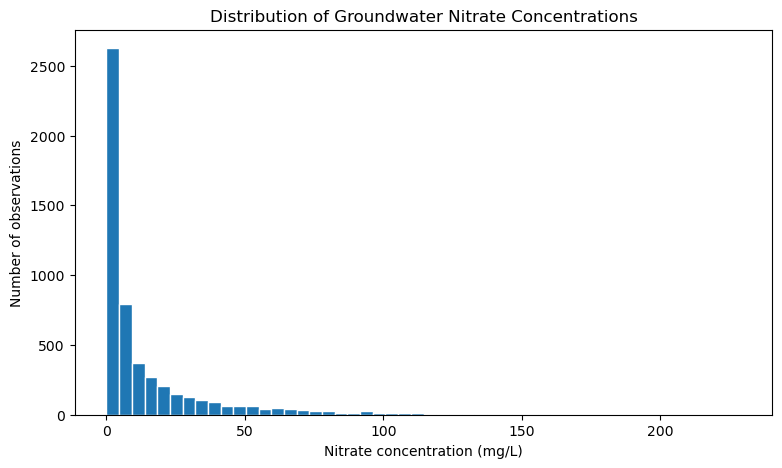

In [8]:
import matplotlib.pyplot as plt
# Summarize nitrate concentrations across all observations
display(df["nitrate_mg_L"].describe())

# Visualize the distribution of nitrate concentrations
plt.figure(figsize=(9, 5))

plt.hist(df["nitrate_mg_L"], bins=50, edgecolor="white")

plt.xlabel("Nitrate concentration (mg/L)")
plt.ylabel("Number of observations")
plt.title("Distribution of Groundwater Nitrate Concentrations")

plt.show()


## 4. Environmental Predictors vs. Nitrate

### 4.1 Soil and terrain relationships

**Objective:** Review previously computed Spearman relationships using one median summary per well. The underlying groundwater, soil, and terrain data have not been reprocessed.


In [9]:

# Select nitrate and key soil/terrain features
features = [
    "soil_slopegradwta",
    "soil_aws0150wta",
    "soil_brockdepmin",
    "elevation_m",
    "topographic_position"
]

# Summarize nitrate and environmental features by well
well_data = df.groupby("gm_well_id")[
    ["nitrate_mg_L"] + features
].median()

# Calculate Spearman correlations with nitrate
correlations = well_data[features].corrwith(
    well_data["nitrate_mg_L"], method="spearman"
)

# Show correlations and available well counts
results = pd.DataFrame({
    "spearman_r": correlations.round(3),
    "n_wells": well_data[features].notna().sum()
})

display(results.sort_values("spearman_r", ascending=False))


,spearman_r,n_wells
soil_aws0150wta,0.137,1993
topographic_position,0.069,1993
soil_brockdepmin,0.040,603
elevation_m,-0.253,1993
soil_slopegradwta,-0.361,1993


**Preliminary findings — Soil & Terrain**

- Soil slope (ρ = -0.361) and elevation (ρ = -0.253) show the strongest associations with nitrate.
- Lower slope and elevation are associated with higher nitrate concentrations.
- These relationships may reflect agricultural land use and spatial patterns rather than direct causal effects.
- Bedrock depth has limited coverage (603 wells).

**ML implication:** Retain soil and terrain predictors for further evaluation. Test whether their associations remain useful under spatially independent validation.


### 4.2 Climate relationships

**Objective:** Review associations with historical and antecedent PRISM climate features. Interpret these as exploratory associations, potentially confounded by spatial/seasonal patterns.


In [10]:
# Select historical and antecedent climate predictors
climate_features = [
    "historical_mean_annual_precip_mm",
    "previous_3_complete_months_precip_mm",
    "previous_12_complete_months_precip_mm",
    "historical_mean_temperature_c",
    "previous_3_complete_months_temperature_c",
    "previous_12_complete_months_temperature_c"
]

# Summarize climate and nitrate by well for an initial spatial comparison
climate_by_well = df.groupby("gm_well_id")[
    ["nitrate_mg_L"] + climate_features
].median()

# Calculate Spearman correlations and data availability
climate_results = pd.DataFrame({
    "spearman_r": climate_by_well[climate_features].corrwith(
        climate_by_well["nitrate_mg_L"], method="spearman"
    ).round(3),
    "n_wells": climate_by_well[climate_features].notna().sum()
})

display(climate_results.sort_values("spearman_r"))


,spearman_r,n_wells
historical_mean_annual_precip_mm,-0.418,1993
previous_12_complete_months_precip_mm,-0.173,1993
previous_3_complete_months_precip_mm,-0.098,1993
previous_12_complete_months_temperature_c,-0.029,1993
historical_mean_temperature_c,0.068,1993
previous_3_complete_months_temperature_c,0.265,1993



**Preliminary findings — Climate**

- Historical annual precipitation shows the strongest negative association with nitrate (ρ = -0.418).
- Previous 3-month temperature shows a positive association (ρ = 0.265).
- Other antecedent climate variables show weaker associations.

**ML implication:** Climate variables may provide useful predictors, but associations could reflect spatial and seasonal confounding. These results summarize differences between wells, not within-well temporal responses. Feature redundancy and predictive value must be evaluated under spatial-temporal validation.


## 5. Historical Agricultural Features — Lag-1 EDA

**Objective:** Review the already-computed availability and Spearman correlations of agricultural predictors from the year before each nitrate observation.

**Temporal assumption:** Year *t* nitrate is joined to year *t−1* crop features to represent preceding agricultural conditions and avoid using later-in-year land use; this is **not** evidence that nitrate travels through the aquifer in one year. Maps published after a sampling date also mean these results are **retrospective**, not necessarily deployable at that past date. Consider alternative lag periods only in future analysis.

**Coverage caveat:** A successfully matched crop record or non-missing variable is not proof of complete mapped land cover within a buffer. The DWR polygon footprint represents mapped polygons, not the entire landscape.


In [11]:
# Select key agricultural predictors for the initial EDA.
# Check feature availability separately for each nitrate sampling year.

crop_features = [
    "pct_cropland_500m",
    "pct_veg_berry_500m",
    "crop_cycles_500m",
    "pct_multicrop_1000m",
    "delta_cropland_pp_500m"
]

# Confirm which columns are present in the new dataset.
available_features = [col for col in crop_features if col in df.columns]
print("Available features:", available_features)

# Calculate the percentage of non-missing values by sampling year.
crop_availability = (
    df.groupby("year")[available_features]
    .apply(lambda group: group.notna().mean() * 100)
    .round(1)
)

display(crop_availability)

# Verify the one-year lag between nitrate and crop data.
display(pd.crosstab(df["year"], df["crop_year"]))


Available features: ['pct_cropland_500m', 'pct_veg_berry_500m', 'crop_cycles_500m', 'pct_multicrop_1000m', 'delta_cropland_pp_500m']


,pct_cropland_500m,pct_veg_berry_500m,crop_cycles_500m,pct_multicrop_1000m,delta_cropland_pp_500m
year,,,,,
2022,99.6,99.6,99.4,99.7,99.6
2023,99.4,99.4,99.2,99.6,99.3
2024,99.8,99.8,99.6,99.8,99.8
2025,99.8,99.8,99.4,99.8,99.7


crop_year,2021,2022,2023,2024
year,,,,
2022,1455,0,0,0
2023,0,1298,0,0
2024,0,0,1252,0
2025,0,0,0,1275



**Key Findings — Historical Crop Availability**

- Annual agricultural predictors are available for more than 99% of nitrate observations in each sampling year (2022–2025).
- All observations were successfully matched to the preceding crop-mapping year (lag-1).
- Feature availability does not imply complete spatial mapping coverage.
- The lag-1 approach supports retrospective analysis, but does not establish the actual groundwater nitrate transport time.


In [12]:

# Summarize repeated nitrate samples within each well-year.
# Compare agricultural predictors with nitrate separately by year.

well_year = (
    df.groupby(["gm_well_id", "year"], as_index=False)[
        ["nitrate_mg_L", *available_features]
    ].median()
)

# Calculate Spearman correlations for each nitrate sampling year.
yearly_corr = pd.DataFrame({
    year: group[available_features].corrwith(
        group["nitrate_mg_L"],
        method="spearman"
    )
    for year, group in well_year.groupby("year")
})

print("Unique well-year records:", len(well_year))

print("\nWells per year:")
display(well_year.groupby("year")["gm_well_id"].nunique())

print("\nSpearman correlations with nitrate:")
display(yearly_corr.round(3))


Unique well-year records: 5178

Wells per year:


year
2022    1379
2023    1280
2024    1245
2025    1274
Name: gm_well_id, dtype: int64


Spearman correlations with nitrate:


,2022,2023,2024,2025
pct_cropland_500m,0.263,0.244,0.239,0.224
pct_veg_berry_500m,0.346,0.334,0.333,0.294
crop_cycles_500m,0.365,0.390,0.353,0.350
pct_multicrop_1000m,0.365,0.350,0.369,0.323
delta_cropland_pp_500m,0.028,0.079,-0.070,-0.061



**Key Findings — Historical Agricultural Predictors**

- Crop cycles showed the strongest and most consistent positive correlation with groundwater nitrate (ρ = 0.350–0.390).
- Multicrop area (ρ = 0.323–0.369) and vegetable/berry cultivation (ρ = 0.294–0.346) also showed consistent positive associations.
- Total cropland had weaker but consistently positive correlations (ρ = 0.224–0.263).
- Annual changes in cropland percentage showed weak and inconsistent correlations with nitrate.
- Compared with the previous 2023-only agricultural analysis, the expanded dataset revealed stronger relationships. However, differences in spatial coverage and sample composition prevent attributing this improvement solely to temporal alignment.

**ML Implication:** Retain agricultural intensity and crop composition as candidate predictors. Evaluate their additional predictive value after accounting for geography, soil, and climate. Correlations do not establish causality or justify final feature selection.


## 6. Feature Relationships & Redundancy

**Objective:** Review the previously computed seven-feature Spearman heatmap, focusing on how agricultural intensity relates to other agriculture variables, slope, elevation, and historical precipitation.

**Scope:** Seven intentionally selected example features, not all 147 columns. Identifiers, target values, coverage metadata and other variables are excluded from this display, and no feature is removed based on correlation alone.


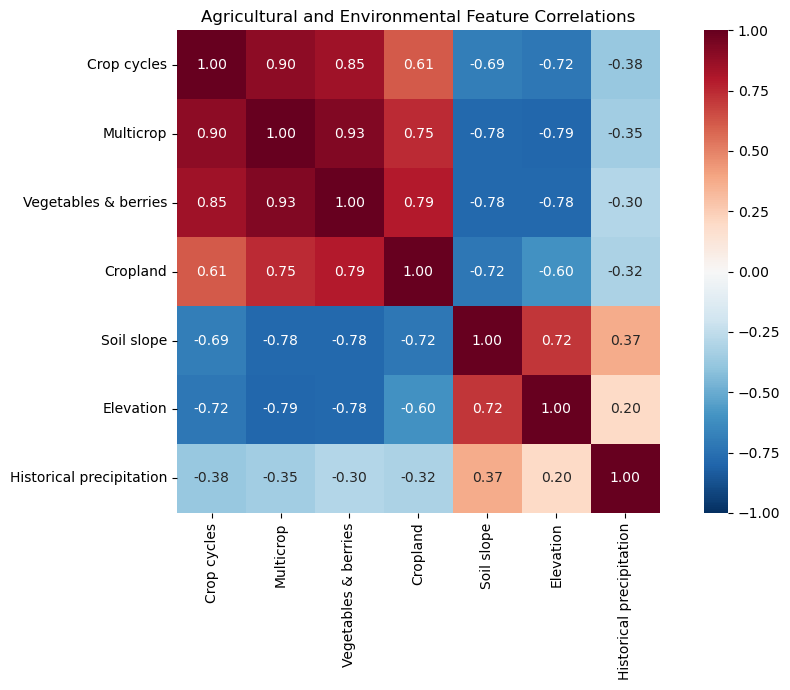

In [13]:

# Compare agricultural and environmental predictors.
# Use one median value per well-year to avoid overweighting repeated samples.

import matplotlib.pyplot as plt
import seaborn as sns

feature_labels = {
    "crop_cycles_500m": "Crop cycles",
    "pct_multicrop_1000m": "Multicrop",
    "pct_veg_berry_500m": "Vegetables & berries",
    "pct_cropland_500m": "Cropland",
    "soil_slopegradwta": "Soil slope",
    "elevation_m": "Elevation",
    "historical_mean_annual_precip_mm": "Historical precipitation"
}

well_year_features = (
    df.groupby(["gm_well_id", "year"])[list(feature_labels)]
    .median()
)

# Calculate Spearman correlations between predictors.
feature_corr = well_year_features.corr(method="spearman")
plot_corr = feature_corr.rename(
    index=feature_labels,
    columns=feature_labels
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    plot_corr,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Agricultural and Environmental Feature Correlations")
plt.tight_layout()
plt.show()


**Key Findings — Agricultural and Environmental Redundancy (saved heatmap)**

- Crop cycles and multicrop area: **ρ = +0.90**.
- Multicrop and vegetables/berries: **ρ = +0.93**.
- Agricultural predictors are negatively correlated with soil slope (e.g., multicrop vs. slope **ρ = −0.78**) and elevation (multicrop vs. elevation **ρ = −0.79**).
- Soil slope and elevation: **ρ = +0.72**.

These values are associations among *predictors*, not direct effects on nitrate. Their geographic structure could explain part of the agricultural–nitrate associations. Collinearity and contributions to predictive performance still require group-aware model validation; no variables are excluded here.


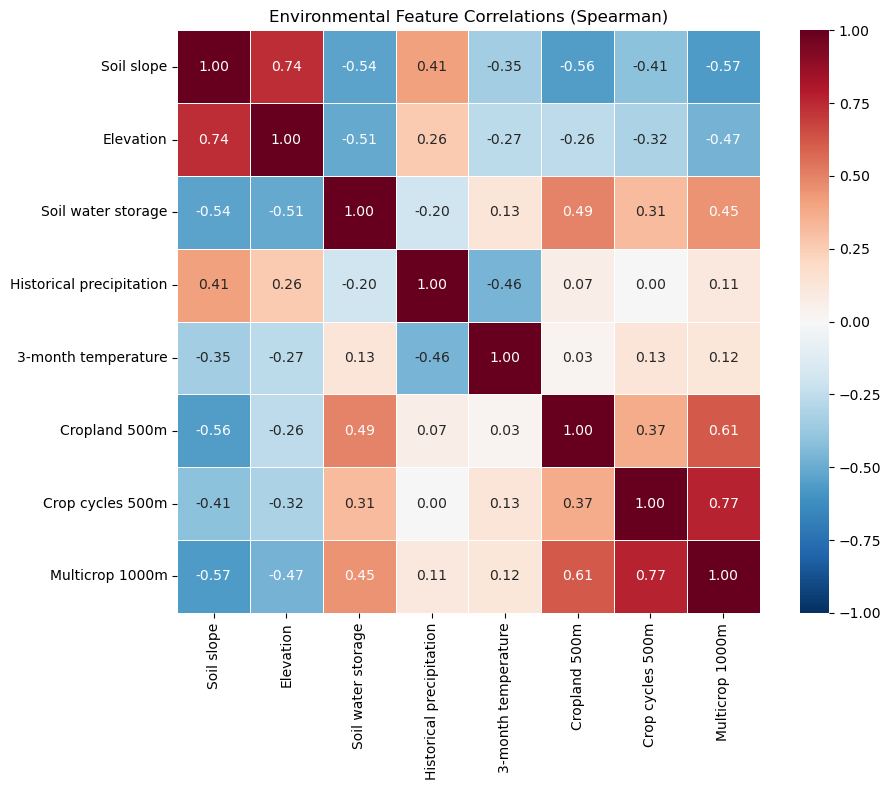

In [20]:
# ARCHIVE ONLY — legacy 2023 crop-snapshot analysis.
# Saved results are preserved; do not rerun on the lag-1 dataset.
if False:

    import seaborn as sns

    # Use shorter feature names to make the plot easier to read
    labels = {
        "soil_slopegradwta": "Soil slope",
        "elevation_m": "Elevation",
        "soil_aws0150wta": "Soil water storage",
        "historical_mean_annual_precip_mm": "Historical precipitation",
        "previous_3_complete_months_temperature_c": "3-month temperature",
        "pct_cropland_500m_2023": "Cropland 500m",
        "crop_cycles_500m_2023": "Crop cycles 500m",
        "pct_multicrop_1000m_2023": "Multicrop 1000m"
    }

    # Rename columns and rows for visualization only
    plot_corr = feature_corr.rename(index=labels, columns=labels)

    # Visualize Spearman correlations between environmental predictors
    plt.figure(figsize=(10, 8))

    sns.heatmap(
        plot_corr,
        annot=True,
        fmt=".2f",
        cmap="RdBu_r",
        center=0,
        vmin=-1,
        vmax=1,
        linewidths=0.5,
        square=True
    )

    plt.title("Environmental Feature Correlations (Spearman)")
    plt.tight_layout()
    plt.show()


**Key Findings — Feature Redundancy**

- Crop cycles and multicrop percentage are strongly correlated (ρ = 0.77), suggesting overlapping information about agricultural intensity.
- Soil slope and elevation are also strongly correlated (ρ = 0.74), potentially reflecting the geography of Salinas Valley.
- Cropland and multicrop percentage show moderate-to-strong correlation (ρ = 0.61).
- Several environmental predictors appear to capture related spatial or agricultural characteristics.

**ML Implication:** Retain these features initially, but evaluate redundancy and their individual predictive contributions. Correlation alone is not sufficient justification for removing variables.
